# 📂 6장 · 파일에서, 웹에서: 데이터 불러오기 (실습 노트북)

『빅데이터분석 with 파이썬』 6장의 **05. 파이썬 실습**과 **미니 프로젝트**를 그대로 따라 하는 노트북입니다. 실습 번호는 책과 같습니다.

| 표시 | 뜻 | 실습 |
|---|---|---|
| ★ 필수 | 수업 시간에 모두 함께 | 6-1 ~ 6-6 |
| ☆ 선택 | 자습이나 심화 | 6-7 ~ 6-10 |

**데이터** (모두 강의 자료 「6장_강의자료.zip」 안에 있습니다)
- 에어코리아 최종확정 측정자료에서 서울 측정소만 남긴 2025년 월별 엑셀 12개 (원본과 같은 열, 같은 시트 이름)
- 기상청 기상자료개방포털에서 받은 서울 시간자료 CSV (CP949, 받은 그대로)
- 한국전력거래소 시간별 전국 전력수요량 CSV 5개 (2021~2025년, 공공데이터포털에서 받은 그대로)
- **연습 사이트**: 위 미세먼지 값으로 만든 작은 웹사이트. 코랩 안에서 켜고 접속하므로 바깥 사이트에 부담을 주지 않습니다.

코드 셀은 **위에서부터 차례로** 실행하십시오(`Shift + Enter`). 아래 셀은 위에서 만든 변수를 이어서 씁니다. 웹 실습(6-4~6-10)은 6-4에서 켠 연습 사이트를 계속 씁니다.

## 0 · 준비

① 그래프의 한글이 네모(□)로 깨지지 않게 해 주는 **koreanize-matplotlib**를 설치합니다.

② 왼쪽 📁 파일 창에 「6장_강의자료.zip」을 끌어다 올린 뒤, 아래 둘째 셀을 실행해 압축을 풉니다. 「6장_강의자료」 폴더가 생기면 준비가 끝납니다.

In [1]:
!pip install -q koreanize-matplotlib

**데이터 받기** (깃허브 저장소판에서 덧붙인 셀) — 아래 셀은 이 장이 쓰는 강의 자료 파일을 저장소의 `data` 폴더에서 코랩으로 내려받습니다.

In [ ]:
# 이 장의 강의 자료 파일을 책 깃허브 저장소에서 받아 옵니다.
# (파일을 코랩 왼쪽 📁 파일 창에 직접 끌어다 올렸다면 이 셀은 건너뛰어도 됩니다.)
import os, urllib.parse, urllib.request
BASE = "https://raw.githubusercontent.com/yeonu69/bigdata-python-book/main/ch06/data/"
for f in [
    "6장_강의자료.zip",
]:
    if not os.path.exists(f):
        urllib.request.urlretrieve(BASE + urllib.parse.quote(f), f)
    print("준비됨:", f, f"({os.path.getsize(f) / 1e6:.1f} MB)")

In [2]:
import os
if not os.path.exists("6장_강의자료"):
    !unzip -q -O utf-8 6장_강의자료.zip
print(sorted(os.listdir("6장_강의자료")))

['기상청_서울_시간자료_원본.csv', '에어코리아_서울_2025', '연습사이트', '전력수요']


## 05. 파이썬 실습: 파일 열두 개와 웹페이지 스물여덟 쪽

05절의 실습은 두 갈래입니다. 6-1~6-3은 파일 길이고, 6-4~6-6은 웹 길입니다. 6-6의 끝에서 두 길이 같은 답을 주는지 맞춰 봅니다. 시작하기 전에 강의 자료 「6장_강의자료.zip」을 코랩에 올려 풀어 두십시오.

#### [파이썬 실습 6-1 ★] 인코딩 오류를 만나고 고치기

기상자료개방포털에서 받은 서울 날씨 CSV를 그대로 읽어 보고, 오류가 나면 인코딩을 바꾸어 다시 읽으시오. "서울"이 두 인코딩에서 몇 바이트인지도 확인하시오.

① 아무것도 정하지 않고 읽어 오류 메시지를 봅니다. ② `encoding="cp949"`로 다시 읽습니다. ③ 글자를 바이트로 바꾸어 봅니다.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
try:
    import koreanize_matplotlib            # 코랩: 한글 글꼴을 자동으로 설정
except ImportError:                        # 나눔고딕 파일이 이미 있는 컴퓨터
    import glob, os
    import matplotlib.font_manager as fm
    for f in glob.glob(os.path.expanduser("~/.fonts/Nanum*.ttf")):
        fm.fontManager.addfont(f)
    plt.rcParams["font.family"] = "NanumGothic"
plt.rcParams["axes.unicode_minus"] = False

DATA = "6장_강의자료"
PATH = DATA + "/기상청_서울_시간자료_원본.csv"   # 기상자료개방포털에서 받은 그대로

try:
    w = pd.read_csv(PATH)                        # 아무것도 정하지 않으면 UTF-8로 읽는다
except UnicodeDecodeError as e:
    print("오류:", e)

w = pd.read_csv(PATH, encoding="cp949")          # 한글 윈도의 옛 방식으로 다시 읽기
print("크기:", w.shape)
print(w.iloc[:3, [1, 2, 3, 11]].to_string())

for enc in ["utf-8", "cp949"]:                   # 같은 글자, 다른 바이트
    b = "서울".encode(enc)
    print(f"{enc:>6}: {len(b)}바이트 {b.hex(' ')}")
print("파일 맨 앞 4바이트:", open(PATH, "rb").read(4).hex(" "), "→", open(PATH, "rb").read(4).decode("cp949"))

오류: 'utf-8' codec can't decode byte 0xc1 in position 0: invalid start byte
크기: (24, 38)
  지점명                일시  기온(°C)  습도(%)
0  서울  2026-10-16 01:00    16.9     74
1  서울  2026-10-16 02:00    16.3     77
2  서울  2026-10-16 03:00    16.7     79
 utf-8: 6바이트 ec 84 9c ec 9a b8
 cp949: 4바이트 bc ad bf ef
파일 맨 앞 4바이트: c1 f6 c1 a1 → 지점


판다스는 기본으로 UTF-8을 가정합니다. 그런데 이 파일의 첫 바이트는 `c1`입니다. UTF-8 규칙에서는 `c1`로 시작하는 글자가 없습니다. 그래서 "0번째 바이트 0xc1을 풀 수 없다"는 오류가 났습니다. CP949로 읽자 24행 38열의 표가 되었습니다. 첫 네 바이트 `c1 f6 c1 a1`은 CP949로 "지점"입니다. "서울"은 UTF-8로 6바이트, CP949로 4바이트로 책의 그림과 같습니다.

> **[코드 읽기] `try`와 `except`**
>
> `try:` 아래의 코드를 먼저 해 보고, 그 안에서 오류가 나면 멈추는 대신 `except 오류이름 as e:` 아래로 넘어갑니다. `e`에는 오류 메시지가 담깁니다. 오류가 날 줄 알면서 메시지를 보여 주고 싶을 때, 또는 오류가 나도 다음 일을 이어 가야 할 때 씁니다.

#### [파이썬 실습 6-2 ★] 엑셀 한 파일의 신원 확인과 24시

2025년 1월 서울 파일을 읽고, 크기와 자료형, 측정망, 측정소 수를 확인하시오. 측정일시를 날짜로 바꾸되, 24시를 다음 날 0시로 처리하시오.

① 읽는 데 걸린 시간을 잽니다. ② 첫 줄과 열의 자료형을 봅니다. ③ 측정일시를 그대로 바꾸어 오류를 확인합니다. ④ 몫과 나머지로 날짜와 시를 나누어 바꿉니다.

In [4]:
import time
f = DATA + "/에어코리아_서울_2025/2025년 1월.xlsx"
t0 = time.time()
one = pd.read_excel(f)
print("읽는 데 걸린 시간:", round(time.time() - t0, 1), "초")
print("크기:", one.shape)
print(one.dtypes.to_string())
print(one.head(3).to_string())
print(one["망"].value_counts().to_dict())
print("측정소 수:", one["측정소명"].nunique())
print("측정일시의 시:", one["측정일시"].min() % 100, "~", one["측정일시"].max() % 100)

try:
    pd.to_datetime(one["측정일시"].astype(str), format="%Y%m%d%H")
except ValueError as e:
    print("날짜로 바꾸지 못함:", str(e).split(". You")[0])

day = pd.to_datetime((one["측정일시"] // 100).astype(str), format="%Y%m%d")   # 앞 8자리 = 날짜
one["일시"] = day + pd.to_timedelta(one["측정일시"] % 100, unit="h")          # 뒤 2자리 = 시
print(one[["측정일시", "일시"]].iloc[22:26].to_string())

읽는 데 걸린 시간: 3.2 초
크기: (29760, 12)
지역           str
망            str
측정소코드      int64
측정소명         str
측정일시       int64
SO2      float64
CO       float64
O3       float64
NO2      float64
PM10     float64
PM25     float64
주소           str
      지역     망   측정소코드 측정소명        측정일시     SO2    CO      O3     NO2  PM10  PM25             주소
0  서울 중구  도시대기  111121   중구  2025010101  0.0034  0.73  0.0010  0.0306  21.0  12.0  서울 중구 덕수궁길 15
1  서울 중구  도시대기  111121   중구  2025010102  0.0032  0.63  0.0011  0.0307  21.0  13.0  서울 중구 덕수궁길 15
2  서울 중구  도시대기  111121   중구  2025010103  0.0034  0.54  0.0025  0.0301  19.0  12.0  서울 중구 덕수궁길 15
{'도시대기': 18600, '도로변대기': 11160}
측정소 수: 40
측정일시의 시: 1 ~ 24
날짜로 바꾸지 못함: unconverted data remains when parsing with format "%Y%m%d%H": "4"
          측정일시                  일시
22  2025010123 2025-01-01 23:00:00
23  2025010124 2025-01-02 00:00:00
24  2025010201 2025-01-02 01:00:00
25  2025010202 2025-01-02 02:00:00


서울 행만 남긴 작은 파일(29,760행)도 읽는 데 3.1초가 걸렸습니다. 측정소는 40곳이고, 도시대기 25곳과 도로변대기 15곳입니다. 29,760 = 40 × 31 × 24이므로 한 측정소가 한 시간에 한 줄씩입니다. 자료형에서 측정일시는 정수(`int64`)입니다. 글자 열은 판다스 3에서는 `str`로, 코랩의 판다스 2에서는 `object`로 보입니다.

`format="%Y%m%d%H"`로 그대로 바꾸려 하자 오류가 났습니다. 2025010124의 "24"는 시가 될 수 없어 마지막 "4"가 남았다는 뜻입니다. (식 6-6)대로 몫으로 날짜를 만들고 나머지만큼 시간을 더하자, 2025010124가 1월 2일 0시가 되었습니다.

#### [파이썬 실습 6-3 ★] 엑셀 12개를 한 표로

2025년 서울 파일 12개를 모두 찾아 달 순서로 줄 세우고, 하나로 합치시오. 빠진 달, 열 이름, 행 수를 검산하고 달마다 PM2.5 평균을 그리시오.

① `glob`으로 파일을 찾고 글자 순서와 달 순서를 견줍니다. ② 반복문으로 읽으며 어느 파일에서 왔는지 표시합니다. ③ `concat`으로 합치고 (식 6-4)와 (식 6-5)로 검산합니다. ④ 도시대기 측정소만 골라 달마다 평균을 그립니다.

파일 수: 12
글자 순서: ['2025년 10월.xlsx', '2025년 11월.xlsx', '2025년 12월.xlsx', '2025년 1월.xlsx']
달 순서: ['2025년 1월.xlsx', '2025년 2월.xlsx', '2025년 3월.xlsx', '2025년 4월.xlsx']
빠진 달: []


열 이름이 모두 같은가: True
합친 크기: (350400, 13)
행 수 검산: 350400 = 350400
달      1      2      3      4      5      6      7      8      9      10     11     12
행   29760  26880  29760  28800  29760  28800  29760  29760  28800  29760  28800  29760
기대  29760  26880  29760  28800  29760  28800  29760  29760  28800  29760  28800  29760


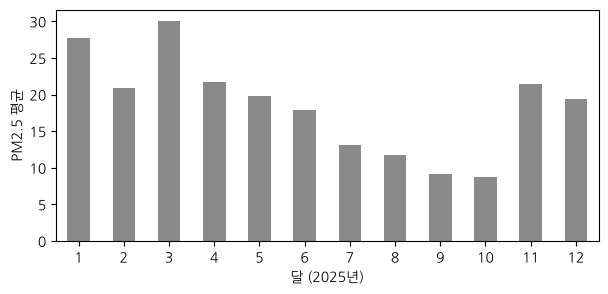

In [5]:
import glob, os, re
files = glob.glob(DATA + "/에어코리아_서울_2025/*.xlsx")
print("파일 수:", len(files))
print("글자 순서:", [os.path.basename(f) for f in sorted(files)][:4])

def month_of(path):                              # 파일 이름에서 '숫자+월'을 찾아 숫자만
    return int(re.search(r"(\d+)월", path).group(1))

files = sorted(files, key=month_of)
print("달 순서:", [os.path.basename(f) for f in files][:4])
print("빠진 달:", sorted(set(range(1, 13)) - {month_of(f) for f in files}))

parts = []
for f in files:
    t = pd.read_excel(f)
    t["파일"] = os.path.basename(f)              # 어느 파일에서 왔는지 표시
    parts.append(t)
print("열 이름이 모두 같은가:", all(list(p.columns) == list(parts[0].columns) for p in parts))

air = pd.concat(parts, ignore_index=True)
print("합친 크기:", air.shape)
print("행 수 검산:", sum(len(p) for p in parts), "=", len(air))

air["달"] = air["측정일시"] // 10000 % 100
days = air.groupby("달")["측정일시"].apply(lambda s: (s // 100).nunique())
check = pd.DataFrame({"행": air.groupby("달").size(), "기대": days * 24 * air["측정소코드"].nunique()})
print(check.T.to_string())

city = air[air["망"] == "도시대기"]
city.groupby("달")["PM25"].mean().plot.bar(color="#8a8a8a", figsize=(7, 3))
plt.xlabel("달 (2025년)")
plt.ylabel("PM2.5 평균")
plt.xticks(rotation=0)
plt.show()

글자 순서로는 10월이 1월보다 앞에 섰습니다. `key=month_of`를 주자 1월부터 바르게 섰습니다. 열두 달이 모두 있고, 열 이름도 모두 같습니다. 합친 표는 350,400행으로 파일별 행 수의 합과 같습니다. 달마다 실제 행 수도 기대 행 수(40곳 × 날 수 × 24)와 모두 같습니다. 2월은 [예제 6-3]대로 26,880행입니다.

그래프에서 PM2.5는 봄(3월)에 가장 높고 가을(9~10월)에 가장 낮습니다.

> **[코드 읽기] `sorted(목록, key=함수)`**
>
> `sorted( )`는 목록을 작은 것부터 줄 세웁니다. 글자는 글자끼리 앞에서부터 견줍니다. `key=month_of`를 주면 원소마다 `month_of(원소)`를 계산하고, 그 값으로 줄 세웁니다. 여기서는 파일 이름에서 꺼낸 달 숫자(1~12)로 줄 세운 것입니다. `re.search(r"(\d+)월", path)`는 "숫자가 하나 이상 이어지고 바로 뒤에 '월'"인 곳을 찾는 정규 표현식입니다.

#### [파이썬 실습 6-4 ★] 요청과 응답, 그리고 robots.txt

연습 사이트를 켜고, 측정소 목록 1쪽을 요청하시오. 기본 User-Agent와 직접 정한 User-Agent로 각각 요청해 상태 코드를 견주고, robots.txt로 어느 경로를 가져가도 되는지 확인하시오.

① 연습 사이트를 켭니다. ② 아무 머리글 없이 요청합니다. ③ 이름과 목적을 적은 User-Agent로 다시 요청합니다. ④ robots.txt를 읽어 경로마다 허락을 묻습니다.

In [6]:
import subprocess, sys, time
import requests

SITE = DATA + "/연습사이트"
server = subprocess.Popen([sys.executable, "serve.py", "8000"], cwd=SITE)   # 연습 사이트 켜기
time.sleep(2)
BASE = "http://localhost:8000"

r = requests.get(BASE + "/list/1.html")
print("상태 코드:", r.status_code)
print("기본 User-Agent:", requests.utils.default_user_agent())

HEAD = {"User-Agent": "data-class-bot/1.0 (book ch6 practice)"}   # 누구인지, 왜 왔는지 (영문만)
r = requests.get(BASE + "/list/1.html", headers=HEAD)
print("상태 코드:", r.status_code, "|", r.headers["Content-Type"], "|", len(r.text), "글자")
print(r.text[:120])
print("없는 쪽:", requests.get(BASE + "/list/9.html", headers=HEAD).status_code)

from urllib import robotparser
rp = robotparser.RobotFileParser(BASE + "/robots.txt")
rp.read()
for path in ["/list/1.html", "/station/111121.html", "/admin/index.html"]:
    print(f"{path:22} 가져가도 되나: {rp.can_fetch(HEAD['User-Agent'], BASE + path)}")
print("요청 사이에 쉴 시간:", rp.crawl_delay("*"), "초")

공기 기록 연습장: http://localhost:8000/


상태 코드: 403
기본 User-Agent: python-requests/2.34.2
상태 코드: 200 | text/html; charset=utf-8 | 1836 글자
<!doctype html>
<html lang="ko">
<head>
<meta charset="utf-8">
<title>측정소 목록 1쪽 | 공기 기록 연습장</title>
<link rel="styleshee
없는 쪽: 404
/list/1.html           가져가도 되나: True
/station/111121.html   가져가도 되나: True
/admin/index.html      가져가도 되나: False
요청 사이에 쉴 시간: 1 초


처음 요청은 403으로 거절되었습니다. requests는 User-Agent에 `python-requests/2.34.2`라고 적어 보냅니다. 연습 사이트는 이런 기본값을 받지 않도록 만들어 두었습니다. 실제 사이트에도 이런 곳이 많습니다. 이름과 목적을 적자 200과 함께 HTML 1,836글자를 받았습니다. 없는 쪽은 404입니다.

robots.txt는 목록과 측정소 페이지는 허락하고, /admin/은 막았습니다. 요청 사이에는 1초를 쉬어 달라고 적어 두었습니다. 다음 실습부터 이 두 가지를 그대로 지킵니다. 하나 더, 머리글에는 영문자만 쓸 수 있습니다. User-Agent에 한글을 넣으면 `UnicodeEncodeError`가 납니다.

#### [파이썬 실습 6-5 ★] 뷰티풀수프로 표 한 쪽 읽기

6-4에서 받은 목록 1쪽을 파싱하고, 측정소 표의 줄을 모두 찾아 데이터프레임으로 만드시오. "다음" 링크의 주소도 찾으시오.

① `BeautifulSoup( )`으로 나무 구조를 만듭니다. ② `find( )`로 표 하나를, `find_all( )`로 줄을 모두 찾습니다. ③ 줄마다 칸의 글자와 링크를 꺼내 사전으로 모읍니다. ④ class가 "next"인 링크를 찾습니다.

In [7]:
from bs4 import BeautifulSoup

soup = BeautifulSoup(r.text, "html.parser")       # 글자 → 나무 구조
print(soup.title.text)
print(soup.find("h1").text)

rows = soup.find("table", class_="stations").find("tbody").find_all("tr")
print("줄 수:", len(rows))
print(rows[0])

recs = []
for tr in rows:
    td = tr.find_all("td")
    a = td[1].find("a")
    recs.append({"구": td[0].text, "측정소": a.text, "코드": td[2].text, "링크": a["href"]})
page1 = pd.DataFrame(recs)
print(page1.head(3).to_string())
print("다음 쪽 링크:", soup.find("a", class_="next")["href"])

측정소 목록 1쪽 | 공기 기록 연습장
측정소 목록
줄 수: 10
<tr><td class="gu">중구</td><td class="name"><a href="../station/111121.html">중구</a></td><td class="code">111121</td></tr>
     구  측정소      코드                      링크
0   중구   중구  111121  ../station/111121.html
1  종로구  종로구  111123  ../station/111123.html
2  용산구  용산구  111131  ../station/111131.html
다음 쪽 링크: 2.html


`find("table", class_="stations")`로 표를 찾고, 그 안의 `tbody`에서 `tr`을 모두 찾으니 10줄이었습니다. 첫 줄을 찍어 보면 칸(td)이 세 개입니다. 둘째 칸에는 `<a href="…">` 링크가 있습니다. 태그의 글자는 `.text`로, 속성은 `a["href"]`처럼 사전처럼 꺼냅니다. `class`는 파이썬의 예약어라서 `class_`로 씁니다.

링크는 `../station/111121.html`처럼 "지금 페이지에서 한 칸 위로 올라가서"라는 상대 주소입니다. 다음 실습에서 `urljoin( )`으로 온전한 주소로 바꿉니다.

#### [파이썬 실습 6-6 ★] 여러 쪽을 돌며 모으고, 파일과 맞추기

"다음" 링크가 없을 때까지 목록을 넘기며 측정소 25곳을 모으시오. 측정소 페이지마다 달 평균 표를 읽어 한 표로 만들고, [파이썬 실습 6-3]에서 파일로 계산한 값과 맞추어 보시오.

① 1초 쉬고 요청하고 파싱하는 함수를 만듭니다. ② `while` 반복으로 목록 쪽을 넘깁니다. ③ 측정소 25쪽을 돌며 표를 모읍니다. ④ 파일 길의 달 평균과 합쳐 같은 칸을 셉니다. ⑤ 구마다 평균을 그립니다.

측정소: 25 곳 | 첫 주소: http://localhost:8000/station/111121.html


웹에서 모은 표: (300, 5) | 걸린 시간: 25 초
    코드   구  달  PM25  시간
111251 관악구  4   NaN   0
111251 관악구  5   NaN   0
111281 금천구 12   NaN   0
맞춰 본 칸: 300 | 같은 칸: 300 (둘 다 빈칸 3 개 포함)


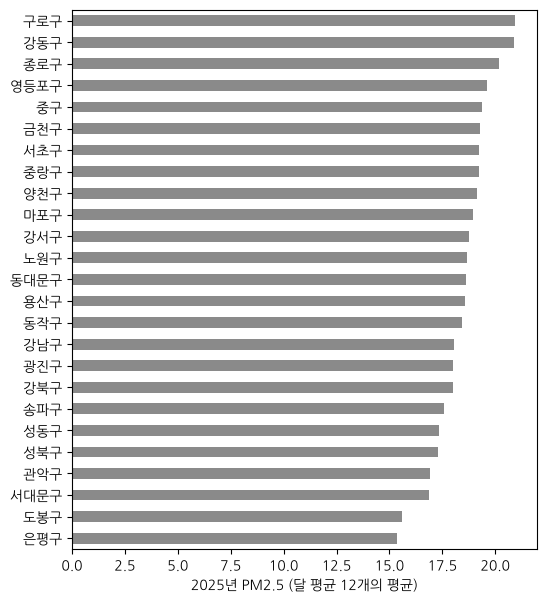

가장 낮은 구: 은평구 15.4 | 가장 높은 구: 구로구 20.9


In [8]:
from urllib.parse import urljoin

def get_soup(url):
    time.sleep(rp.crawl_delay("*"))               # robots.txt의 약속대로 쉬었다가
    res = requests.get(url, headers=HEAD)
    res.raise_for_status()                        # 200이 아니면 여기서 멈춘다
    return BeautifulSoup(res.text, "html.parser")

stations, url = [], BASE + "/list/1.html"
while url:                                        # '다음' 링크가 없을 때까지
    s = get_soup(url)
    for tr in s.find("table", class_="stations").find("tbody").find_all("tr"):
        td = tr.find_all("td")
        stations.append({"구": td[0].text, "측정소": td[1].text, "코드": td[2].text,
                         "주소": urljoin(url, td[1].find("a")["href"])})
    nxt = s.find("a", class_="next")
    url = urljoin(url, nxt["href"]) if nxt else None
st = pd.DataFrame(stations)
print("측정소:", len(st), "곳 | 첫 주소:", st["주소"][0])

t0, rows = time.time(), []
for one_st in st.itertuples():
    s = get_soup(one_st.주소)
    for tr in s.find("table", class_="monthly").find("tbody").find_all("tr"):
        td = [x.text for x in tr.find_all("td")]
        rows.append({"코드": one_st.코드, "구": one_st.구, "달": int(td[0][5:]),
                     "PM25": pd.to_numeric(td[2], errors="coerce"),   # '-'는 빈칸(NaN)으로
                     "시간": int(td[3])})
web = pd.DataFrame(rows)
print("웹에서 모은 표:", web.shape, "| 걸린 시간:", round(time.time() - t0), "초")
print(web[web["PM25"].isna()].to_string(index=False))

# 파일 길(6-3)과 웹 길이 같은 답을 주는지 맞춰 보기
fm = (city.groupby(["측정소코드", "달"])["PM25"].mean().round(1)
          .reset_index().rename(columns={"측정소코드": "코드", "PM25": "파일"}))
fm["코드"] = fm["코드"].astype(str)
both = web.merge(fm, on=["코드", "달"])
same = (both["PM25"] == both["파일"]) | (both["PM25"].isna() & both["파일"].isna())
print("맞춰 본 칸:", len(both), "| 같은 칸:", same.sum(), "(둘 다 빈칸", (both["PM25"].isna() & both["파일"].isna()).sum(), "개 포함)")

gu = web.groupby("구")["PM25"].mean().sort_values()
gu.plot.barh(color="#8a8a8a", figsize=(6, 7))
plt.xlabel("2025년 PM2.5 (달 평균 12개의 평균)")
plt.ylabel("")
plt.show()
print("가장 낮은 구:", gu.index[0], gu.iloc[0].round(1), "| 가장 높은 구:", gu.index[-1], gu.iloc[-1].round(1))

목록 세 쪽에서 25곳을 모았고, 측정소 페이지 25쪽에서 300줄(25곳 × 12달)을 모았습니다. 요청 28번 사이마다 1초씩 쉬었기 때문에 25초쯤 걸렸습니다.

웹 표에는 "-"로 적힌 칸이 세 개 있었습니다. `float("-")`는 오류가 나므로 `pd.to_numeric(..., errors="coerce")`로 빈칸(NaN)으로 바꾸었습니다. 이 세 칸이 3.6의 관악구 4·5월과 금천구 12월입니다. 파일로 계산한 값과 맞추어 보니 300칸이 모두 같았습니다. 두 길이 같은 답을 준 것입니다.

> **[코드 읽기] `while 조건:`과 `urljoin( )`**
>
> `for`는 정해진 목록을 처음부터 끝까지 돕니다. `while 조건:`은 조건이 참인 동안 되풀이합니다. 여기서는 `url`이 비어 있지 않은 동안 돕니다. 마지막 쪽에서 "다음" 링크가 없으면 `url = None`이 되어 멈춥니다. 몇 쪽인지 미리 몰라도 끝까지 갈 수 있습니다. `urljoin(지금 주소, 상대 주소)`는 "지금 페이지에서 본 상대 주소"를 온전한 주소로 바꿉니다.

#### [파이썬 실습 6-7 ☆] read_html 한 줄로 표 읽기

측정소 페이지 하나의 HTML을 `pd.read_html( )`로 읽어, 페이지 속 표를 바로 데이터프레임으로 만드시오.

In [9]:
import io
html = requests.get(st["주소"][0], headers=HEAD).text
tables = pd.read_html(io.StringIO(html))          # 페이지 속 <table>을 모두 표로
print("표 개수:", len(tables))
print(tables[0].head(3).to_string())

표 개수: 1
         달  PM10 평균  PM2.5 평균  측정 시간
0  2025-01     40.0      30.0    729
1  2025-02     32.6      21.7    669
2  2025-03     46.2      31.5    737


`read_html( )`은 페이지 속 `<table>`을 모두 찾아 데이터프레임의 목록으로 돌려줍니다. 표가 깔끔하면 뷰티풀수프 없이 한 줄로 끝납니다. 다만 표 밖의 정보(주소, 링크)는 가져오지 못합니다. 칸 안에 링크가 있을 때는 6-5처럼 직접 파싱해야 합니다.

#### [파이썬 실습 6-8 ☆] 동적 페이지: 빈 칸 뒤의 JSON 찾기


측정소 페이지의 "날마다 PM2.5" 칸을 requests로 읽어 보고, 그 칸이 부르는 JSON을 직접 받아 날마다 PM2.5를 그리시오.

파이썬이 받은 칸: 그래프를 불러오는 중입니다…
칸이 부르는 자료: ../api/daily_111121.json
JSON 열쇠: ['station', 'code', 'unit', 'daily']
[{'date': '2025-01-01', 'pm25': 20.8}, {'date': '2025-01-02', 'pm25': 19.2}]
(365, 2) | 가장 높은 날: 2025-01-21 111.6


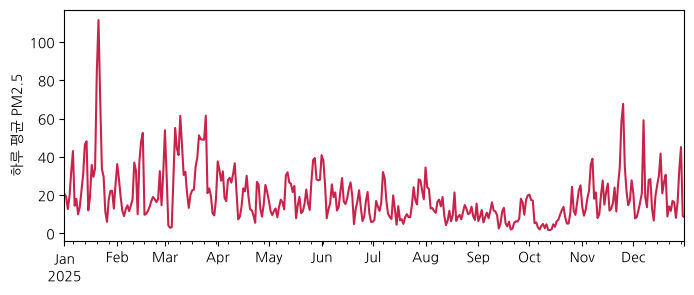

In [10]:
s = get_soup(st["주소"][0])
box = s.find("div", id="daily")
print("파이썬이 받은 칸:", box.text)
print("칸이 부르는 자료:", box["data-src"])

js = requests.get(urljoin(st["주소"][0], box["data-src"]), headers=HEAD).json()
print("JSON 열쇠:", list(js.keys()))
print(js["daily"][:2])
d = pd.DataFrame(js["daily"])
d["date"] = pd.to_datetime(d["date"])
print(d.shape, "| 가장 높은 날:", d.loc[d["pm25"].idxmax(), "date"].date(), d["pm25"].max())
d.plot(x="date", y="pm25", color="#C8234B", legend=False, figsize=(8, 3))
plt.xlabel("")
plt.ylabel("하루 평균 PM2.5")
plt.show()

브라우저로 보면 이 칸에 그래프가 있습니다. 그런데 파이썬이 받은 칸에는 "그래프를 불러오는 중입니다…"뿐입니다. 그래프는 페이지가 열린 뒤 자바스크립트가 JSON을 받아 그리기 때문입니다. requests는 자바스크립트를 실행하지 않습니다.

이럴 때는 페이지가 부르는 JSON 주소를 찾습니다. 여기서는 칸의 `data-src` 속성에 적혀 있었습니다. 실제 사이트에서는 브라우저 개발자 도구의 "네트워크" 탭에서 찾습니다. JSON을 받아 보니 365일 치가 있었습니다. 중구는 1월 21일이 111.6으로 가장 높았습니다.

#### [파이썬 실습 6-9 ☆] 저장 형식 견주기와 나누어 읽기

6-3에서 합친 표를 CSV, 파케이, 엑셀로 저장하고 크기와 쓰기·읽기 시간을 견주시오. 큰 CSV를 10만 줄씩 나누어 읽으며 PM2.5가 75를 넘은 측정을 세시오.

In [11]:
os.makedirs("저장", exist_ok=True)
keep = air.drop(columns=["파일"])
for kind in ["csv", "parquet", "xlsx"]:
    path = "저장/서울_2025." + kind
    t0 = time.time()
    if kind == "csv": keep.to_csv(path, index=False)
    elif kind == "parquet": keep.to_parquet(path, index=False)
    else: keep.to_excel(path, index=False)
    t_w = time.time() - t0
    t0 = time.time()
    back = {"csv": pd.read_csv, "parquet": pd.read_parquet, "xlsx": pd.read_excel}[kind](path)
    print(f"{kind:>7}: {os.path.getsize(path) / 1e6:5.1f} MB | 쓰기 {t_w:4.1f}초 | 읽기 {time.time() - t0:4.1f}초 | {back.shape}")

n_bad = 0
for chunk in pd.read_csv("저장/서울_2025.csv", chunksize=100_000):   # 10만 줄씩 나눠 읽기
    n_bad += (chunk["PM25"] > 75).sum()
print("PM2.5가 75를 넘은 측정:", n_bad, "번")

    csv:  47.5 MB | 쓰기  3.3초 | 읽기  1.3초 | (350400, 13)


parquet:   2.4 MB | 쓰기  0.1초 | 읽기  0.5초 | (350400, 13)


   xlsx:  18.2 MB | 쓰기 59.1초 | 읽기 36.5초 | (350400, 13)


PM2.5가 75를 넘은 측정: 2879 번


같은 350,400행이 CSV로 47.5MB, 엑셀로 18.2MB, 파케이로 2.4MB입니다. 엑셀은 쓰는 데 1분, 읽는 데 40초쯤 걸렸습니다. 파케이는 둘 다 1초가 안 됩니다. 3.4에서 원본으로 잰 차이와 같은 방향입니다.

`chunksize=100_000`을 주면 `read_csv( )`가 표를 한꺼번에 읽지 않습니다. 10만 줄씩 조각을 내어 하나씩 돌려줍니다. 메모리에 다 들어가지 않는 큰 파일도 이렇게 조각마다 세어 더하면 됩니다. 2025년 서울에서 PM2.5가 75(매우 나쁨 기준)를 넘은 측정은 2,879번이었습니다. 측정소 40곳의 한 시간 값을 모두 센 것입니다.

#### [파이썬 실습 6-10 ☆] 같아 보이는 이름, 다른 글자

파일 이름 "2025년 1월.xlsx"를 NFD로 바꾸어 원래 이름과 같은지, 글자 수가 몇인지 견주시오.

In [12]:
import unicodedata
name = "2025년 1월.xlsx"
mac = unicodedata.normalize("NFD", name)          # 맥에서 압축한 파일 이름의 모양
print(name == mac, len(name), len(mac))
print([hex(ord(c)) for c in mac[4:7]])
print("다시 합치면:", unicodedata.normalize("NFC", mac) == name)

server.terminate()                                 # 연습 사이트 끄기

False 13 17
['0x1102', '0x1167', '0x11ab']
다시 합치면: True


NFC 이름은 13글자, NFD 이름은 17글자입니다. "년"과 "월"이 각각 낱자 세 개로 나뉘어 네 글자가 늘었습니다. 둘을 `==`로 견주면 다르다고 나옵니다. NFC로 다시 합치면 같아집니다. 맥에서 받은 파일이 `glob`에 걸리지 않으면 이 실습을 떠올리십시오.

## [미니 프로젝트 6] 5년 치 전력수요 파일을 한 표로

**질문.** 한국전력거래소는 전국 전력수요를 한 해에 파일 하나씩 공개합니다. 다섯 해 치 파일을 한 표로 모으면, 해마다 전기를 가장 많이 쓴 때는 언제였을까요? 2장 미니 프로젝트에서는 누군가 이미 합쳐 둔 파일을 썼습니다. 이번에는 그 파일을 직접 만듭니다.

**데이터.** 공공데이터포털에서 받은 "한국전력거래소 시간별 전국 전력수요량" CSV 5개(2021~2025년)입니다. 강의 자료의 「전력수요」 폴더에 받은 그대로 들어 있습니다. 한 행이 하루이고, 열은 날짜와 1시~24시의 수요(MW) 25개입니다. 인코딩은 CP949입니다.


**1단계: 데이터 신원 확인**([파이썬 실습 6-1] 응용). 2021년 파일을 읽고 크기, 첫 두 행, 자료형을 확인하시오.

In [13]:
P = DATA + "/전력수요/한국전력거래소_시간별_전국_전력수요량_2021.csv"
y21 = pd.read_csv(P, encoding="cp949")
print(y21.shape)
print(y21.iloc[:2, :6].to_string())
print(y21.dtypes.value_counts().to_dict())

(365, 25)
           날짜     1시     2시     3시     4시     5시
0  2021-01-01  64942  62593  60905  59889  59638
1  2021-01-02  60658  58603  57309  56663  56733
{dtype('int64'): 24, <StringDtype(na_value=nan)>: 1}


365행 25열입니다. 하루가 한 줄이고, 24개 시각이 열로 나란히 있습니다. 숫자 열 24개는 모두 정수이고, 날짜는 글자입니다. 이런 모양을 3장에서 "넓은 표"라고 불렀습니다.

**2단계: 다섯 파일을 합치고 검산하기**([파이썬 실습 6-3] 응용). 다섯 파일을 모두 읽어 행 수와 열 이름을 확인하고 합치시오. 날짜가 빈 행, 같은 날짜, 빈칸을 세시오.

In [14]:
files = sorted(glob.glob(DATA + "/전력수요/*.csv"))
parts = [pd.read_csv(f, encoding="cp949") for f in files]
print([len(p) for p in parts])
print("열이 모두 같은가:", all(list(p.columns) == list(parts[0].columns) for p in parts))
kpx = pd.concat(parts, ignore_index=True)
print("합친 크기:", kpx.shape, "| 날짜가 빈 행:", kpx["날짜"].isna().sum())
print(kpx[kpx["날짜"].isna()].iloc[:, :4].to_string())
kpx = kpx.dropna(subset=["날짜"])
kpx = kpx.astype({c: "int64" for c in kpx.columns[1:]})   # 빈 행 때문에 실수가 된 열을 정수로
print("빈 행을 지운 뒤:", kpx.shape, "| 같은 날짜:", kpx["날짜"].duplicated().sum(), "| 빈칸:", kpx.isna().sum().sum())

[365, 365, 365, 366, 366]
열이 모두 같은가: True
합친 크기: (1827, 25) | 날짜가 빈 행: 1
       날짜  1시  2시  3시
1826  NaN NaN NaN NaN
빈 행을 지운 뒤: (1826, 25) | 같은 날짜: 0 | 빈칸: 0


행 수는 365, 365, 365, 366, 366입니다. 2024년은 윤년이니 366이 맞습니다. 그런데 2025년도 366입니다. 합친 표에서 날짜가 빈 행을 찾으니 마지막 한 줄이 모두 비어 있었습니다. 2025년 파일 끝에 쉼표만 있는 빈 줄이 붙어 있던 것입니다. 이 줄을 지우자 1,826일이 되었고, 같은 날짜와 빈칸은 없었습니다. 2021~2025년의 날 수(365 × 4 + 1)와 같습니다. 빈 줄 때문에 정수 열이 실수가 되었으므로 다시 정수로 바꾸었습니다.

**3단계: 넓은 표를 긴 표로**([파이썬 실습 6-2] 응용). `melt( )`로 한 시간이 한 줄인 표를 만들고, 날짜와 시로 일시를 만드시오. 이 파일도 시가 1~24로 적혀 있습니다.

In [15]:
long = kpx.melt(id_vars="날짜", var_name="시", value_name="수요")    # 넓은 표 → 긴 표
long["시"] = long["시"].str.replace("시", "").astype(int)
long["일시"] = pd.to_datetime(long["날짜"]) + pd.to_timedelta(long["시"], unit="h")
long = long.sort_values("일시").reset_index(drop=True)
print(long.shape)
print(long.head(3).to_string())
print("시간 간격:", long["일시"].diff().value_counts().to_dict())

(43824, 4)
           날짜  시     수요                  일시
0  2021-01-01  1  64942 2021-01-01 01:00:00
1  2021-01-01  2  62593 2021-01-01 02:00:00
2  2021-01-01  3  60905 2021-01-01 03:00:00
시간 간격: {Timedelta('0 days 01:00:00'): 43823}


1,826일 × 24시간 = 43,824줄이 되었습니다. 일시를 줄 세운 뒤 이웃한 두 줄의 간격을 세어 보니 43,823개가 모두 정확히 한 시간이었습니다. 빠진 시각도, 겹친 시각도 없다는 뜻입니다. 24시는 에어코리아 자료처럼 다음 날 0시가 되었습니다.

**4단계: 답하기.** 해마다 수요가 가장 컸던 날과 시를 찾고, 해마다 시각별 평균 수요를 한 그림에 그리시오.

        날짜  시    수요
2021-07-27 18 91141
2022-12-23 11 94509
2023-08-07 17 93615
2024-08-20 17 97115
2025-08-25 18 95951


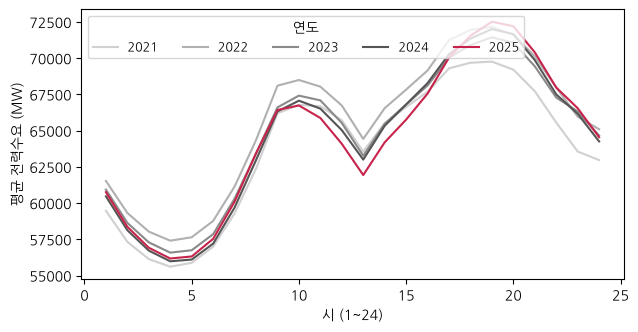

In [16]:
long["연도"] = long["일시"].dt.year
top = long.loc[long.groupby(long["날짜"].str[:4])["수요"].idxmax(), ["날짜", "시", "수요"]]
print(top.to_string(index=False))
prof = long.pivot_table(index="시", columns=long["날짜"].str[:4], values="수요", aggfunc="mean")
prof.plot(figsize=(7, 3.5), color=["#d0d0d0", "#b0b0b0", "#8a8a8a", "#555555", "#C8234B"])
plt.xlabel("시 (1~24)")
plt.ylabel("평균 전력수요 (MW)")
plt.legend(title="연도", ncol=5, fontsize=9, loc="upper left")
plt.show()

다섯 해 가운데 네 해는 여름(7~8월) 오후 17~18시에 수요가 가장 컸습니다. 2022년만 겨울(12월 23일 11시)이었습니다. 다섯 해 가운데 가장 큰 값은 2024년 8월 20일 17시의 97,115MW입니다. 평균 그래프에서는 하루에 두 번 높아집니다. 오전 10시 무렵과 저녁 19시 무렵입니다. 2025년은 낮 12~15시 평균이 다섯 해 가운데 가장 낮고, 저녁 19시 평균(72,524MW)은 가장 높습니다.

**5단계: 한계 쓰기.** 이 분석이 아직 모르는 것을 [표 6-1]처럼 표로 쓰시오. "이 수요에는 무엇이 빠져 있는가"(예: 전력시장을 거치지 않는 자가용 태양광)를 반드시 다루시오. 2025년 낮 수요가 낮은 까닭을 이 자료만으로 말할 수 있는지도 쓰시오.

**제출물.** 그림 2장(해마다 시각별 평균 수요, 가장 큰 날 하루의 24시간), 표 1개(해마다 최대 수요의 날짜·시·값), 결론 5문장 이내.

**[표 6-2] 미니 프로젝트 채점 기준**

| 항목(비중) | 상 | 중 | 하 |
|---|---|---|---|
| 데이터 점검(20%) | 인코딩, 다섯 파일의 열 이름, 행 수, 빈 줄을 모두 확인하고 처리 방법을 밝힘 | 빈 줄은 지웠으나 까닭(파일 끝 빈 줄)을 찾지 않음 | 확인 없이 바로 합침 |
| 기준선 비교(20%) | 1,826일 × 24 = 43,824와 한 시간 간격으로 검산함 | 행 수만 셈 | 검산하지 않음 |
| 기법 적용(30%) | 파일 찾기·합치기·melt·24시 처리가 맞고 코드가 다시 돌아감 | 결과는 맞으나 파일 이름을 하나씩 손으로 적음 | 코드가 돌지 않거나 24시가 틀림 |
| 해석과 한계(30%) | 해마다 최대 수요를 바르게 읽고, 자료에 빠진 것과 원인을 말할 수 없음을 씀 | 한계를 한두 가지 씀 | 그래프만 보고 원인을 단정함 |

## ✏️ [연습문제 6-2] 24시 바꾸기

측정일시 2025013124를 몫과 나머지로 나누고, 실제 시각으로 바꾸는 코드를 쓰시오.

In [17]:
# 여기에 직접 코드를 써 보십시오.

### 정답 코드

직접 해 본 뒤에 실행해 보십시오.

In [18]:
print(2025013124 // 100, 2025013124 % 100)
t = pd.to_datetime("20250131", format="%Y%m%d") + pd.to_timedelta(24, unit="h")
print(t)

20250131 24
2025-02-01 00:00:00


## ✏️ [연습문제 6-6] 뷰티풀수프로 찾기

다음 HTML에서 (가) 첫 기사 제목, (나) 모든 링크 주소의 목록, (다) 날짜를 꺼내는 코드를 쓰시오.

```text
<ul class="news">
  <li><a href="/a1">첫 기사</a></li>
  <li><a href="/a2">둘째 기사</a></li>
</ul>
<p class="date">2025-10-20</p>
```

In [19]:
# 여기에 직접 코드를 써 보십시오.

### 정답 코드

직접 해 본 뒤에 실행해 보십시오.

In [20]:
from bs4 import BeautifulSoup
html = """<ul class="news">
  <li><a href="/a1">첫 기사</a></li>
  <li><a href="/a2">둘째 기사</a></li>
</ul>
<p class="date">2025-10-20</p>"""
s = BeautifulSoup(html, "html.parser")
print(s.find("li").text)
print([a["href"] for a in s.find_all("a")])
print(s.find("p", class_="date").text)

첫 기사
['/a1', '/a2']
2025-10-20
